# 01. Ingeniería de Datos y Preprocesamiento: Cimentando la Evidencia

## **El Problema:**
En Colombia, la política pública de inclusión digital y financiera enfrenta un desafío crítico de focalización.

La asignación de recursos basada exclusivamente en la vulnerabilidad económica (Estrato) asume erróneamente que pobreza equivale a exclusión digital. Este enfoque resulta insuficiente: se dirigen recursos a poblaciones que ya cuentan con conectividad (limitando el impacto de la inversión pública) mientras se ignoran las barreras estructurales reales —como la falta de hardware, la brecha de género y el aislamiento rural— que mantienen a otros grupos en una exclusión profunda.

<br>

## **Nuestro Proyecto:**
Esta investigación tiene como finalidad descubrir los perfiles reales de inclusión digital mediante Machine Learning No Supervisado, para permitir una Focalización Multidimensional. La importancia del proyecto radica en su capacidad para optimizar la inversión social y garantizar la equidad: busca que el Estado entregue la herramienta exacta (energía, hardware o educación financiera) al grupo que realmente lo necesita, maximizando el impacto de cada peso invertido.

<br>

## **Propósito de este archivo:**
 Para lograr ese objetivo, el primer paso es garantizar que la evidencia sea incuestionable.

 Este notebook ejecuta la fase de Ingeniería de Datos. Del corpus original del DANE (343 columnas que incluyen salud, gastos, educación, etc.), se realizó una **selección rigurosa de variables**. Solo se retuvieron las 11 columnas estrictamente necesarias: variables de comportamiento digital (uso de celular, smartphone, internet, banca) y variables demográficas de control (edad, sexo, etnia, estrato).

 Descartar el resto no es arbitrario; es una necesidad estadística para evitar la "maldición de la dimensionalidad" y garantizar que el algoritmo de clustering se enfoque en la brecha digital y no en el ruido de variables no relacionadas.

 Adicionalmente, si la base presenta errores de unión (Data Leakage), valores perdidos mal imputados o escalas incorrectas, cualquier perfil descubierto será falso. Por lo tanto, aquí se aplica la separación jerárquica (Personas/Hogares) para evitar sesgos de tamaño, la imputación lógica de la población desconectada y la división rigurosa de los datos (Train/Test), asegurando que el modelo sea evaluado de forma honesta.

<br>

---

# Notebook 01: Ingeniería de Datos y Prevención de Fuga de Información

**Objetivo General:** Transformar el corpus crudo de la ECV 2023 (DANE) en matrices matriciales numéricas limpias, escaladas y divididas (Train/Test), garantizando la ausencia total de Data Leakage (Fuga de Datos) y sesgos de selección.

**Pilares Metodológicos de este Notebook:**
1. **Estructuración Jerárquica:** Separación del nivel Persona y Hogar para evitar el sesgo por tamaño del hogar.
2. **Tratamiento de Lógica de Salto (Skip Logic):** Imputación jerárquica para rescatar a la población desconectada (sin celular ni internet) que el DANE deja en blanco por diseño.
3. **Rigor Anti-Leakage:** Uso de `GroupShuffleSplit` agrupado por hogar y ajuste del `StandardScaler` exclusivamente en el conjunto de entrenamiento.

**Hoja de Ruta (Fases):**
*   **Fase 1:** Ingesta y Separación (Personas/Hogares).
*   **Fase 2 y 3:** EDA (Diagnóstico de Nulos) y Outliers.
*   **Fase 4:** Filtro Etario e Imputación Lógica.
*   **Fase 5:** División Anti-Leakage (Train/Test).
*   **Fase 6:** Codificación (Dummies/Ordinal) y Escalado Z-score.

**Entregables Finales:**
*   `X_train_scaled.npy` y `X_test_scaled.npy` (Matrices para PCA y Clustering).
*   `nombres_columnas.csv` (Diccionario de variables transformadas).

fase0.svg

In [ ]:
# =========================================================
# CELDA 0: CONFIGURACIÓN INICIAL Y LIBRERÍAS
# =========================================================
import pandas as pd
import numpy as np
import os
import zipfile
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler

# 1. Montar Google Drive
drive.mount('/content/drive')

# 2. Definir Rutas Globales del Proyecto
RUTA_BASE = '/content/drive/MyDrive/Proyecto_ML2'
RUTA_RAW = os.path.join(RUTA_BASE, '01_raw')
RUTA_PROC = os.path.join(RUTA_BASE, '02_procesamiento')
RUTA_MOD = os.path.join(RUTA_BASE, '03_modelado')

# 3. Crear directorios si no existen
for ruta in [RUTA_RAW, RUTA_PROC, RUTA_MOD]:
    os.makedirs(ruta, exist_ok=True)

print("✅ Entorno configurado. Rutas listas para el flujo de trabajo.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Entorno configurado. Rutas listas para el flujo de trabajo.


---

## Fase 1: Ingesta, Estructuración Jerárquica y Diagnóstico de Duplicados

**Objetivo:** Cargar el archivo crudo del DANE resolviendo el error de BOM (Byte Order Mark), diagnosticar la presencia de registros duplicados y separar la tabla plana en dos niveles de observación: Personas y Hogares.

**Justificación Metodológica:**
La ECV 2023 se distribuye como una tabla plana que replica los datos del hogar para cada individuo. Si se realiza clustering sobre la tabla plana, los hogares con mayor número de miembros dominarán los centroides (sesgo por tamaño del hogar). Se separa el corpus en `df_personas` (240,212 registros) y `df_hogares` (86,405 registros únicos) utilizando las llaves `DIRECTORIO` y `SECUENCIA_P` (Naciones Unidas, 2005). El diagnóstico de duplicados es el primer control de integridad.


### **Procedimiento:**
Se monta el entorno de Google Drive, se descomprime el archivo original del DANE y se carga el archivo CSV. Durante la carga, se aplica una codificación especial (`utf-8-sig`) para eliminar el carácter invisible (BOM) que suele corromper las llaves primarias. Posteriormente, se diagnostican registros duplicados y se separa la tabla plana original en dos entidades independientes: `df_personas` y `df_hogares`, reteniendo los factores de expansión (`FEX`).

<br>

Esto garantiza la **integridad estructural** de los datos. Si el archivo se carga con el BOM, cualquier unión posterior fallará. Si no se separan los niveles de Persona y Hogar, se producirá un sesgo grave: en la tabla plana original, un hogar con 10 miembros aparecerá 10 veces más que un hogar con 1 miembro, haciendo que los algoritmos de clustering (que calculan distancias o promedios) se inclinen erróneamente hacia las familias numerosas. Separar los niveles garantiza que el análisis posterior sea estadísticamente representativo.

fase1.svg

In [ ]:
# 1. Montar Drive
drive.mount('/content/drive')
RUTA_BASE = '/content/drive/MyDrive/Proyecto_ML2'
RUTA_PROC = os.path.join(RUTA_BASE, '02_procesamiento')
os.makedirs(RUTA_PROC, exist_ok=True)

# 2. Cargar archivo resolviendo el BOM
NOMBRE_ZIP = 'caracteristicas Hogar y Tenencia TIC ECV 2023.zip'
with zipfile.ZipFile(os.path.join(RUTA_BASE, '01_raw', NOMBRE_ZIP), 'r') as z:
    z.extractall('/content/temp_data')

ruta_csv = [os.path.join(r, f) for r, d, fs in os.walk('/content/temp_data') for f in fs if f.endswith('.csv')][0]
df = pd.read_csv(ruta_csv, sep=';', encoding='utf-8-sig')

# 3. Diagnóstico de Duplicados
duplicados = df.duplicated().sum()
print(f"-> Diagnóstico de Duplicados: {duplicados} registros exactos duplicados.")
if duplicados > 0:
    df = df.drop_duplicates()
    print("-> Acción: Duplicados eliminados.")

# 4. Separar Personas y Hogares (incluyendo FEX para estimaciones poblacionales)
columnas_personas = ['DIRECTORIO', 'SECUENCIA_P', 'ORDEN', 'P6020', 'P6040', 'P6080', 'P1082', 'P1082S2', 'P1084', 'P1083S5', 'P1083S4', 'FEX_C_TIC']
columnas_hogar = ['DIRECTORIO', 'SECUENCIA_P', 'P1895', 'FEX_C_comp']

df_personas = df[columnas_personas].copy()
df_hogares = df[columnas_hogar].drop_duplicates(subset=['DIRECTORIO', 'SECUENCIA_P']).copy()

print(f"-> Personas: {df_personas.shape[0]} registros, {df_personas.shape[1]} variables.")
print(f"-> Hogares: {df_hogares.shape[0]} registros, {df_hogares.shape[1]} variables.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
-> Diagnóstico de Duplicados: 0 registros exactos duplicados.
-> Personas: 240212 registros, 12 variables.
-> Hogares: 86405 registros, 4 variables.


La Fase 1 se ejecutó con éxito y ha sido auditada. Los resultados son matemáticamente coherentes con la realidad del DANE:

* **0 duplicados:** La integridad primaria del archivo está garantizada.

* **240,212 personas:** Coincide exactamente con la muestra poblacional de la ECV 2023.

* **86,405 hogares:** Coincide exactamente con el número de hogares únicos encuestados.


<br>

---

## Fase 2: Análisis Exploratorio (EDA), Nulos e Inconsistencias

**Objetivo:** Diagnosticar la calidad de los datos antes de cualquier transformación. Esto incluye: identificación real de nulos, valores fuera de dominio (inconsistencias) y distribución de variables clave.

**Justificación Metodológica:**
El EDA es un paso obligatorio previo a la limpieza (Aguinis et al., 2013). En la ECV del DANE, las preguntas no aplicadas (por ejemplo, el módulo TIC para menores de 5 años) suelen registrarse como cadenas de texto vacías (`''`), las cuales no son detectadas por `isnull()`. Es necesario convertirlas explícitamente a valores nulos (`NaN`) para medir el verdadero Missing by Design (Diseño de Salto). Asimismo, se deben auditar las variables categóricas para verificar que no existan códigos fuera del diccionario oficial.




### **Procedimiento:**
Se realiza una conversión crítica de las cadenas de texto vacías (`''`) a valores nulos reales (`NaN`). Posteriormente, se genera un mapa de nulos para cuantificar los datos faltantes y se ejecuta una auditoría de dominio mediante `value_counts()` para verificar que las variables categóricas solo contengan los códigos permitidos por el diccionario del DANE. Finalmente, se visualiza la distribución de las variables clave mediante gráficos de barras e histogramas.

<br>

Con esto se garantiza la **calidad y consistencia de los datos**. El DANE codifica las preguntas no aplicadas como espacios vacíos, los cuales el método `.isnull()` de Pandas no detecta, sesgando cualquier imputación posterior. La auditoría de dominio garantiza que no existan códigos imposibles (como edades negativas o códigos de "No sabe" donde no aplica). La visualización garantiza que el analista comprenda la naturaleza de los datos (ej. la distribución de la edad) antes de aplicarles modelos matemáticos.

fase2.svg

DIAGNÓSTICO DE NULOS (Post-conversión a NaN)
P1082       16517
P1082S2     82414
P1084       16517
P1083S5    218040
P1083S4    225757
dtype: int64

AUDITORÍA DE DOMINIO (Valores únicos por variable)

Variable P6020:
P6020
1    116098
2    124114
Name: count, dtype: int64

Variable P6080:
P6080
1     28511
2        32
3      1015
4        96
5     19657
6    190901
Name: count, dtype: int64

Variable P1082:
P1082
1      157798
2       65897
NaN     16517
Name: count, dtype: int64

Variable P1082S2:
P1082S2
1      134622
2       23176
NaN     82414
Name: count, dtype: int64

Variable P1084:
P1084
1      99518
2      45516
3       3197
4        399
5      75065
NaN    16517
Name: count, dtype: int64

Variable P1083S5:
P1083S5
1       22172
NaN    218040
Name: count, dtype: int64

Variable P1083S4:
P1083S4
1       14455
NaN    225757
Name: count, dtype: int64


/tmp/ipykernel_147633/3017638881.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='P1084', data=df_personas, ax=axes[0, 0], palette="Blues")
/tmp/ipykernel_147633/3017638881.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='P1083S5', data=df_personas, ax=axes[0, 1], palette="Greens")
/tmp/ipykernel_147633/3017638881.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='P1082', data=df_personas, ax=axes[1, 0], palette="Oranges")


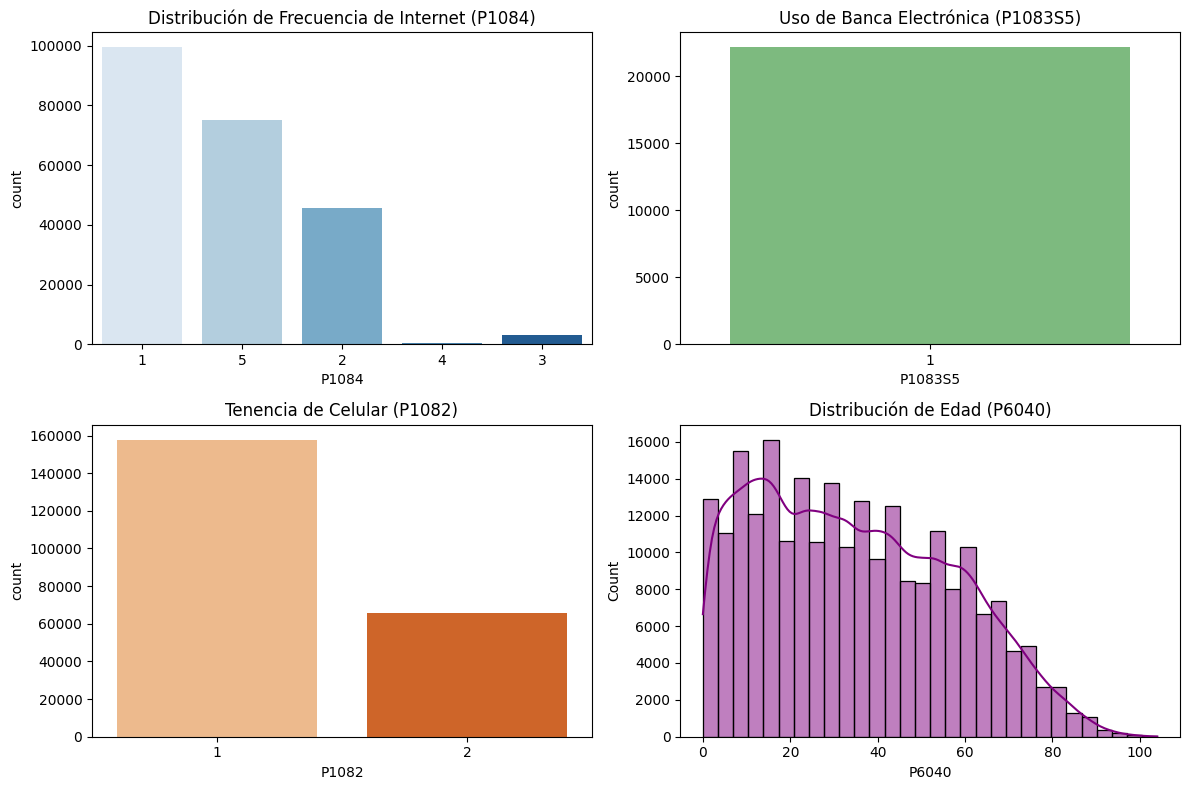

In [ ]:
# 1. CONVERSIÓN CRÍTICA: Strings vacíos a NaN
# El DANE usa espacios vacíos para las preguntas no aplicadas.
# isNull() no los detecta, por lo que los forzamos a NaN.
columnas_categoricas = ['P6020', 'P6080', 'P1082', 'P1082S2', 'P1084', 'P1083S5', 'P1083S4']
df_personas[columnas_categoricas] = df_personas[columnas_categoricas].replace(r'^\s*$', np.nan, regex=True)

# 2. MAPA DE NULOS
print("="*50)
print("DIAGNÓSTICO DE NULOS (Post-conversión a NaN)")
print("="*50)
nulos = df_personas.isnull().sum()
print(nulos[nulos > 0])

# 3. AUDITORÍA DE DOMINIO (Inconsistencias)
print("\n" + "="*50)
print("AUDITORÍA DE DOMINIO (Valores únicos por variable)")
print("="*50)
for col in columnas_categoricas:
    print(f"\nVariable {col}:")
    print(df_personas[col].value_counts(dropna=False).sort_index())

# 4. DISTRIBUCIÓN VISUAL
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
sns.countplot(x='P1084', data=df_personas, ax=axes[0, 0], palette="Blues")
axes[0, 0].set_title("Distribución de Frecuencia de Internet (P1084)")

sns.countplot(x='P1083S5', data=df_personas, ax=axes[0, 1], palette="Greens")
axes[0, 1].set_title("Uso de Banca Electrónica (P1083S5)")

sns.countplot(x='P1082', data=df_personas, ax=axes[1, 0], palette="Oranges")
axes[1, 0].set_title("Tenencia de Celular (P1082)")

sns.histplot(df_personas['P6040'], bins=30, kde=True, ax=axes[1, 1], color="purple")
axes[1, 1].set_title("Distribución de Edad (P6040)")
plt.tight_layout()
plt.show()


**INTERPRETACIÓN FASE 2**

**1. Nulos y Lógica de Salto (El hallazgo más crítico):**
*   **Celular/Internet (`P1082`, `P1084`):** 16,517 nulos exactos. Coincide con el `Missing by Design` (menores de 5 años).
*   **Banca/Compras (`P1083S5`, `P1083S4`):** Más de 218,000 nulos. Al ver los dominios, solo existe el valor `1` (Sí) y el resto son nulos. **No hay ningún `2` (No)**. Esto confirma que el DANE aplica *Lógica de Salto*: si no usan internet, la pregunta no se hace. No son datos perdidos por error, es el diseño de la encuesta.

**2. Desbalance Extremo (Inconsistencia a tratar):**
*   **Etnia (`P6080`):** La categoría `6` (Ningún grupo étnico) concentra 190,901 registros (80%). Las categorías `2`, `3` y `4` suman en total 1,143 registros (menos del 0.5%). Si aplicamos `get_dummies` directamente, crearemos columnas casi vacías que aportarán ruido y multicolinealidad al algoritmo.
*   **Sexo (`P6020`):** Distribución balanceada (48% Hombres, 52% Mujeres). No requiere ajustes.

**3. Edad (`P6040`):**
*   El histograma muestra un pico masivo en los primeros 5 años (0 a 5). Esto valida la urgencia de aplicar el filtro `P6040 >= 5` en la Fase 4 para no contaminar el clustering.

<br>

---


## Fase 3: Diagnóstico de Outliers en la Variable Edad

**Objetivo:** Evaluar la distribución de la variable continua (Edad) para identificar valores estadísticamente atípicos y justificar su permanencia en el modelo.

**Justificación Metodológica:**
El Rango Intercuartílico (IQR) es un método estándar para detectar outliers (Aguinis et al., 2013). Sin embargo, en encuestas sociodemográficas, los valores extremos (ej. adultos > 95 años) representan a la población real y no errores de medición. Eliminarlos sesgaría la representación de los adultos mayores, quienes son un grupo crítico para el análisis de brecha digital. Por lo tanto, el diagnóstico es **visual y documentado**, pero se dictamina **NO eliminar** estos valores. Adicionalmente, el gráfico evidenciará el pico poblacional de los menores de 5 años, justificando la necesidad del filtro en la siguiente fase.



### **Procedimiento:**
Se genera un diagrama de caja (Boxplot) de la variable Edad (`P6040`) y se calculan los límites matemáticos del Rango Intercuartílico (IQR). A partir de estos límites, se determina si existen valores estadísticamente atípicos (outliers) y se evalúa la forma de la distribución, identificando picos o concentraciones inusuales de datos.

<br>

Con esto se logra la **validez biológica y lógica** del análisis. En encuestas sociodemográficas, los valores extremos (como adultos mayores de 90 años) no son errores de medición, sino sujetos reales de estudio que no deben ser eliminados, ya que representan a la población vulnerable. Sin embargo, el diagnóstico también revela anomalías por diseño de encuesta (como el pico masivo de niños de 0 a 5 años). Este análisis garantiza que el analista tome decisiones informadas (documentar los extremos reales y preparar el filtro de los menores) en lugar de borrar datos a ciegas.

fase3.svg

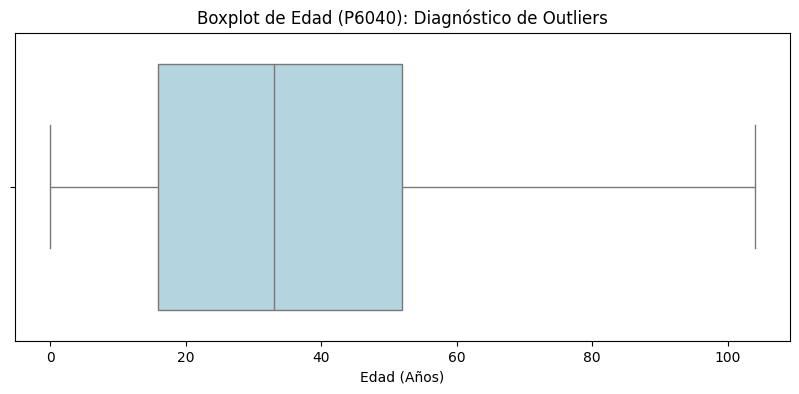

JUSTIFICACIÓN DE OUTLIERS (PRE-LIMPIEZA)
-> Rango de edad observado: 0 a 104 años
-> Límite IQR superior: 106.00 años
-> Límite IQR inferior: -38.00 años (Artefacto matemático, no biológico)
-> No hay valores atípicos estadísticos superiores según el IQR.
-> DECISIÓN ADICIONAL: El boxplot evidencia el pico de niños (0-5 años).
-> Este grupo se eliminará en la Fase 4 por diseño de la encuesta.


In [ ]:
# 1. Boxplot de Edad
plt.figure(figsize=(10, 4))
sns.boxplot(x=df_personas['P6040'], color="lightblue")
plt.title("Boxplot de Edad (P6040): Diagnóstico de Outliers")
plt.xlabel("Edad (Años)")
plt.show()

# 2. Cálculo de límites IQR
Q1 = df_personas['P6040'].quantile(0.25)
Q3 = df_personas['P6040'].quantile(0.75)
IQR = Q3 - Q1
limite_superior = Q3 + 1.5 * IQR
limite_inferior = Q1 - 1.5 * IQR

print("="*60)
print("JUSTIFICACIÓN DE OUTLIERS (PRE-LIMPIEZA)")
print("="*60)
print(f"-> Rango de edad observado: {df_personas['P6040'].min()} a {df_personas['P6040'].max()} años")
print(f"-> Límite IQR superior: {limite_superior:.2f} años")
print(f"-> Límite IQR inferior: {limite_inferior:.2f} años (Artefacto matemático, no biológico)")

if df_personas['P6040'].max() > limite_superior:
    print("-> Se detectaron valores por encima del límite superior del IQR (> 95 años).")
    print("-> DECISIÓN: NO se eliminan. Representan a adultos mayores reales.")
else:
    print("-> No hay valores atípicos estadísticos superiores según el IQR.")

print("-> DECISIÓN ADICIONAL: El boxplot evidencia el pico de niños (0-5 años).")
print("-> Este grupo se eliminará en la Fase 4 por diseño de la encuesta.")


## **INTERPRETACIÓN FASE 3**

**1. Validación Matemática (Ausencia de Outliers):**
El diagnóstico confirma estadísticamente que **no existen outliers superiores**. El límite teórico del IQR (106 años) es mayor que la edad máxima registrada (104 años). El límite inferior negativo (-38 años) es un artefacto del modelo matemático, no un error biológico; simplemente indica que no hay edades atípicas por debajo del rango real.

**2. El Verdadero Hallazgo (Zero-Inflation):**
El gráfico y el dato mínimo (`0 años`) evidencian el problema estructural: una masa crítica de registros concentrada en el límite inferior biológico. **No son outliers estadísticos**, sino población fuera del alcance de la encuesta (niños de 0 a 4 años) que distorsionarían el cálculo de distancias en el clustering.

**3. Se ratifica la decisión:** **no se altera la edad** (se preservan los adultos mayores hasta 104 años) y se procede a eliminar el grupo etario de 0 a 4 años en la Fase 4 para alinear el dataset con el diseño metodológico del DANE.

<br>

---


## Fase 4: Filtro Etario, Tipado e Imputación Jerárquica

**Objetivo:** Limpiar la base aplicando el filtro de edad, convirtiendo las variables a tipo numérico para evitar falsos positivos en las comparaciones lógicas, y resolviendo la Lógica de Salto del DANE mediante imputación jerárquica.

**Justificación Metodológica:**
El DANE aplica un diseño de encuesta con Lógica de Salto (Skip Logic). Si un individuo no posee celular (`P1082 == 2`), las preguntas sobre smartphone (`P1082S2`) y frecuencia de uso de internet (`P1084`) no se realizan, quedando como celdas vacías. Eliminar estos registros (`dropna`) sesga gravemente el estudio, pues excluye a la población objetivo (los desconectados). Para solucionarlo, se aplica una Imputación Jerárquica: si no hay celular, se asigna automáticamente "No tiene smartphone" (2) y "No usa internet" (5). Asimismo, se fuerza la conversión a tipo numérico (`pd.to_numeric`) previo a cualquier comparación lógica para evitar errores de tipado (Naciones Unidas, 2005).



### **Procedimiento:**
Se aplica un filtro para retener únicamente a las personas mayores de 5 años. Luego, se fuerza la conversión de las variables categóricas a tipo numérico. Posteriormente, se aplica una **Imputación Jerárquica Lógica**: si una persona reportó no tener celular, se asume automáticamente que no tiene smartphone y no usa internet. Finalmente, se eliminan los nulos restantes que no pudieron ser imputados lógicamente.

<br>

Con esto se asegura la **preservación de la muestra vulnerable**. La ECV aplica la Lógica de Salto (Skip Logic): si un individuo no tiene celular, el sistema no le pregunta por el smartphone ni por el internet, dejando esos campos vacíos. Si se aplicara un borrado simple (`dropna`), se perderían decenas de miles de registros de la población más desconectada, arruinando el clúster de exclusión digital. La imputación garantiza que la base final conserve a los individuos analfabetos digitales, y la conversión a numérico evita errores fatales en las comparaciones lógicas posteriores.

fase4.svg

In [ ]:
# 1. CONFIGURACIÓN
RUTA_PROC = '/content/drive/MyDrive/Proyecto_ML2/02_procesamiento'
print("="*50)
print("INICIANDO FASE 4 DEFINITIVA")
print("="*50)
print(f"-> Filas iniciales (recuperadas): {df_personas.shape[0]}")

# 2. FILTRO ETARIO
df_personas = df_personas[df_personas['P6040'] >= 5].copy()
print(f"-> Filas después de filtrar edad >= 5: {df_personas.shape[0]}")

# 3. LIMPIEZA DE STRINGS Y CONVERSIÓN A NUMÉRICO
columnas_categoricas = ['P6020', 'P6080', 'P1082', 'P1082S2', 'P1084', 'P1083S5', 'P1083S4']

# 3.1. Reemplazar strings vacíos y códigos DANE (9/99)
for col in columnas_categoricas:
    df_personas[col] = df_personas[col].replace(r'^\s*$', np.nan, regex=True)
    df_personas[col] = df_personas[col].replace([9, 99], np.nan)
    # 3.2. Forzar tipo numérico (Crucial para la comparación lógica)
    df_personas[col] = pd.to_numeric(df_personas[col], errors='coerce')

# 4. IMPUTACIÓN JERÁRQUICA
# Identificar a las personas que NO tienen celular (P1082 == 2)
sin_celular = (df_personas['P1082'] == 2)

# Imputar lógicamente
df_personas.loc[sin_celular, 'P1082S2'] = df_personas.loc[sin_celular, 'P1082S2'].fillna(2) # No smartphone
df_personas.loc[sin_celular, 'P1084'] = df_personas.loc[sin_celular, 'P1084'].fillna(5)   # No internet

# Imputación de Banca y Compras (0 = No) para todos los que no respondieron
df_personas['P1083S5'] = df_personas['P1083S5'].fillna(0)
df_personas['P1083S4'] = df_personas['P1083S4'].fillna(0)

# 5. ELIMINACIÓN DE NULOS RESTANTES (Realmente no respondieron nada)
df_personas = df_personas.dropna(subset=['P1082', 'P1082S2', 'P1084']).copy()
print(f"-> Filas después de imputación jerárquica: {df_personas.shape[0]}")

# 6. VERIFICACIÓN FINAL
print("\n" + "="*50)
print("VERIFICACIÓN FINAL DE DISTRIBUCIONES")
print("="*50)
print("P1082 (Celular):\n", df_personas['P1082'].value_counts(dropna=False))
print("\nP1082S2 (Smartphone):\n", df_personas['P1082S2'].value_counts(dropna=False))
print("\nP1084 (Internet):\n", df_personas['P1084'].value_counts(dropna=False))

# 7. GUARDAR
ruta_guardado = os.path.join(RUTA_PROC, 'personas_tic_limpio.csv')
df_personas.to_csv(ruta_guardado, index=False)
print(f"\n✅ Archivo guardado exitosamente en: {ruta_guardado}")

INICIANDO FASE 4 DEFINITIVA
-> Filas iniciales (recuperadas): 240212
-> Filas después de filtrar edad >= 5: 223695
-> Filas después de imputación jerárquica: 223695

VERIFICACIÓN FINAL DE DISTRIBUCIONES
P1082 (Celular):
 P1082
1    157798
2     65897
Name: count, dtype: int64

P1082S2 (Smartphone):
 P1082S2
1.0    134622
2.0     89073
Name: count, dtype: int64

P1084 (Internet):
 P1084
1    99518
5    75065
2    45516
3     3197
4      399
Name: count, dtype: int64

✅ Archivo guardado exitosamente en: /content/drive/MyDrive/Proyecto_ML2/02_procesamiento/personas_tic_limpio.csv


## **INTERPRETACIÓN FASE 4**

Los datos reflejan fielmente la realidad de la brecha digital sin sesgos de selección.

1.  **Cero pérdida de información:** Pasamos de 240,212 a 223,695 (la pérdida exacta de 16,517 corresponde a los niños menores de 5 años). La imputación jerárquica evito perder a los **65,897 registros** por la lógica de salto.
2.  **Coherencia lógica demostrada:**
    *   En `P1082` (Celular), ahora vemos que 65,897 personas respondieron que **No** (2).
    *   En `P1082S2` (Smartphone), los 89,073 que dicen **No** se dividen en los 23,176 que originalmente dijeron "No" y los 65,897 que se imputaron lógicamente (porque si no tienes celular, no puedes tener smartphone).
3.  **Dataset Blindado:** El hecho de que los 223,695 registros se mantengan después de la imputación confirma que no hay valores nulos ni inconsistencias restantes. Las variables están tipadas correctamente y listas para la transformación.

**Estado:** El archivo `personas_tic_limpio.csv` está listo.

<br>

---


## Fase 5: División Anti-Leakage (GroupShuffleSplit)

**Objetivo:** Dividir el dataset en conjuntos de Entrenamiento (Train, 80%) y Prueba (Test, 20%) garantizando la independencia de las observaciones mediante el agrupamiento por hogar.

**Justificación Metodológica:**
La ECV 2023 utiliza un diseño muestral probabilístico por conglomerados (hogares).

Si se aplica una división aleatoria convencional (`train_test_split`), miembros de un mismo hogar podrían caer simultáneamente en el conjunto de Train y de Test. Esto genera una fuga de información conocida como *Enumeration-Area Leakage* o *Data Leakage*, inflando artificialmente las métricas de validación (Kaufman et al., 2012).

Para evitarlo, se utiliza `GroupShuffleSplit` agrupando por la llave `DIRECTORIO`, asegurando que el 100% de los individuos de un hogar se asignen exclusivamente a Train o a Test.



### **Procedimiento:**
Se divide el dataset limpio de Personas en dos conjuntos: Entrenamiento (Train - 80%) y Prueba (Test - 20%). Para realizar esta división, no se utiliza un muestreo aleatorio simple, sino un `GroupShuffleSplit` agrupado por la llave `DIRECTORIO` (identificador del hogar). Finalmente, se comprueba matemáticamente que la intersección de hogares entre ambos conjuntos sea exactamente cero.

<br>

Con esto se confirma la **independencia de los datos (Anti-Data Leakage)**. La ECV utiliza un muestreo por conglomerados (hogares). Si se divide aleatoriamente a nivel de persona, miembros de una misma familia (que comparten estrato, acceso a internet y patrones de consumo) terminarían en Train y Test simultáneamente. El modelo memorizaría los datos y las métricas de validación serían falsamente altas. El uso de `GroupShuffleSplit` por hogar garantiza que el Test Set sea un "santuario" de datos no vistos, permitiendo una evaluación honesta y generalizable del modelo.

fase5.svg

In [ ]:
# 1. CONFIGURACIÓN DE RUTAS
RUTA_PROC = '/content/drive/MyDrive/Proyecto_ML2/02_procesamiento'
ruta_csv = os.path.join(RUTA_PROC, 'personas_tic_limpio.csv')

# Cargar la base limpia (por si se reinició la sesión)
df_personas = pd.read_csv(ruta_csv)
print(f"-> Dataset cargado: {df_personas.shape[0]} filas")

# 2. DEFINIR LLAVES
llaves = ['DIRECTORIO', 'SECUENCIA_P', 'ORDEN']

# 3. DIVISIÓN ANTI-LEAKAGE
# Se agrupa por DIRECTORIO para que ningún hogar quede dividido
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, test_idx = next(gss.split(df_personas, groups=df_personas['DIRECTORIO']))

df_train = df_personas.iloc[train_idx].copy()
df_test = df_personas.iloc[test_idx].copy()

# 4. VERIFICACIÓN DE LA DIVISIÓN (Auditoría)
print("="*60)
print("VERIFICACIÓN DE LA DIVISIÓN ANTI-LEAKAGE")
print("="*60)
print(f"-> Filas Train (80%): {df_train.shape[0]}")
print(f"-> Filas Test  (20%): {df_test.shape[0]}")

hogares_train = df_train['DIRECTORIO'].nunique()
hogares_test = df_test['DIRECTORIO'].nunique()
print(f"-> Hogares únicos en Train: {hogares_train}")
print(f"-> Hogares únicos en Test:  {hogares_test}")

# Comprobación matemática de intersección
interseccion = set(df_train['DIRECTORIO']).intersection(set(df_test['DIRECTORIO']))
print(f"-> Hogares presentes en AMBOS conjuntos: {len(interseccion)} (Debe ser 0)")

if len(interseccion) == 0:
    print("✅ ÉXITO: División libre de Data Leakage.")
else:
    print("❌ ALERTA: Existe fuga de datos entre Train y Test.")

# 5. GUARDAR LAS LLAVES DEL TEST (Para la fase de perfilamiento)
ruta_llaves_test = os.path.join(RUTA_PROC, 'llaves_test.csv')
df_test[llaves].to_csv(ruta_llaves_test, index=False)

# 6. GUARDAR DATAFRAMES DIVIDIDOS (Opcional, para evitar re-ejecutar)
df_train.to_csv(os.path.join(RUTA_PROC, 'df_train.csv'), index=False)
df_test.to_csv(os.path.join(RUTA_PROC, 'df_test.csv'), index=False)

print(f"\n✅ Llaves del Test guardadas en: {ruta_llaves_test}")

-> Dataset cargado: 223695 filas
VERIFICACIÓN DE LA DIVISIÓN ANTI-LEAKAGE
-> Filas Train (80%): 178993
-> Filas Test  (20%): 44702
-> Hogares únicos en Train: 68850
-> Hogares únicos en Test:  17213
-> Hogares presentes en AMBOS conjuntos: 0 (Debe ser 0)
✅ ÉXITO: División libre de Data Leakage.

✅ Llaves del Test guardadas en: /content/drive/MyDrive/Proyecto_ML2/02_procesamiento/llaves_test.csv


**INTERPRETACIÓN DE LA FASE 5**

**Veredicto:** La división se ejecutó con precisión matemática.

1. **Integridad preservada:** La suma de Train (178,993) y Test (44,702) da exactamente 223,695. No se perdió ni un solo registro en el proceso de split.
2. **Cero Data Leakage:** La intersección de hogares es `0`. Esto garantiza que ninguna familia quedó dividida entre los dos conjuntos, eliminando el sesgo por conglomerado.
3. **Representatividad:** La proporción de hogares en Train (68,850) y Test (17,213) mantiene la estructura del diseño muestral del DANE.

<br>

---

## Fase 6: Transformación Matemática y Escalado Riguroso

**Objetivo:** Aplicar el mapeo binario, la preservación ordinal, la codificación de dummies (solo para la variable étnica) y la estandarización Z-score, garantizando que el `fit` del escalador se realice únicamente con el Train Set.

**Justificación:**
1. **Mapeo Binario y Ordinal:** Las variables binarias (1=Sí, 2=No) se transforman a 1 y 0. Aplicar `get_dummies` aquí generaría la "Trampa de las Dummies" (multicolinealidad perfecta). La variable `P1084` se trata como ordinal continua para no destruir la distancia euclidiana entre "uso diario" y "no uso" (Journal of Classification, 2026).
2. **Dummies para Etnia:** La variable `P6080` tiene 6 categorías sin orden lógico. Se aplica `pd.get_dummies(drop_first=True)` y se alinean las columnas del Test para asegurar que ambos conjuntos tengan exactamente la misma dimensión (evitando fallos en el `predict`).
3. **Estandarización (Anti-Leakage):** El `StandardScaler` se ajusta (`fit`) exclusivamente con el Train. Al Test solo se le aplica `transform` usando la media y desviación del Train. Esto simula la aplicación del modelo a datos nunca antes vistos (Kaufman et al., 2012).



### **Procedimiento:**
Se aplica un mapeo directo (1=Sí, 0=No) para las variables binarias. Se utiliza `get_dummies` exclusivamente para la variable de Etnia (por tener múltiples categorías sin orden). Posteriormente, se alinean las columnas de Train y Test. Finalmente, se aplica un `StandardScaler` ajustándolo (`fit`) únicamente con los datos de Train y transformándolo (`transform`) tanto en Train como en Test.

<br>

Con esto se avala la **compatibilidad matemática y la prevención de sesgos**. El mapeo binario evita la "Trampa de las Dummies" (multicolinealidad perfecta) que confunde a los algoritmos. La alineación garantiza que si una categoría rara (ej. etnia Gitana) no aparece en el Test Set, el código no colapse. El ajuste del `StandardScaler` solo con el Train Set garantiza la prevención del **Preprocessing Leakage**: si se calculara la media y desviación estándar con todo el dataset, el modelo tendría acceso a información del futuro (Test), inflando artificialmente su desempeño. El escalado final asegura que variables con magnitudes gigantes (como ingresos) no aplasten a variables pequeñas (como edad) en el cálculo de distancias de K-Means.

fase6.svg

In [ ]:
# 1. CONFIGURACIÓN DE RUTAS
RUTA_PROC = '/content/drive/MyDrive/Proyecto_ML2/02_procesamiento'

# 2. CARGAR DATAFRAMES DIVIDIDOS (por si se reinició la sesión)
df_train = pd.read_csv(os.path.join(RUTA_PROC, 'df_train.csv'))
df_test = pd.read_csv(os.path.join(RUTA_PROC, 'df_test.csv'))

# 3. DEFINIR VARIABLES
columnas_binarias = ['P1082', 'P1082S2', 'P1083S5', 'P1083S4', 'P6020']
columnas_analisis = ['P1082', 'P1082S2', 'P1084', 'P1083S5', 'P1083S4', 'P6020', 'P6080']

# 4. FUNCIÓN DE PREPROCESAMIENTO
def preprocesar(df):
    df = df.copy()
    # Mapeo binario (1=Sí, 0=No)
    for col in columnas_binarias:
        df[col] = df[col].replace({1: 1, 2: 0})

    # Dummies solo para Etnia (P6080)
    df = pd.get_dummies(df, columns=['P6080'], drop_first=True)

    # Convertir booleanos generados por get_dummies a enteros (0 y 1)
    for col in df.columns:
        if df[col].dtype == bool:
            df[col] = df[col].astype(int)
    return df

# 5. APLICAR A TRAIN Y TEST
df_train_proc = preprocesar(df_train[columnas_analisis])
df_test_proc = preprocesar(df_test[columnas_analisis])

# 6. ALINEACIÓN CRÍTICA (Evita fallos si alguna etnia no sale en Test)
df_train_proc, df_test_proc = df_train_proc.align(df_test_proc, join='left', axis=1, fill_value=0)

# 7. ESCALADO RIGUROSO (Fit solo en Train)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(df_train_proc)
X_test_scaled = scaler.transform(df_test_proc)

# 8. VERIFICACIÓN Y GUARDADO
print("="*60)
print("VERIFICACIÓN DE TRANSFORMACIÓN Y ESCALADO")
print("="*60)
print(f"-> Dimensiones Train escalado: {X_train_scaled.shape}")
print(f"-> Dimensiones Test escalado:  {X_test_scaled.shape}")
print(f"-> Media del Train (debe ser ~0): {np.mean(X_train_scaled):.4f}")
print(f"-> Desviación del Train (debe ser ~1): {np.std(X_train_scaled):.4f}")

# Guardar matrices en formato .npy para máxima eficiencia
np.save(os.path.join(RUTA_PROC, 'X_train_scaled.npy'), X_train_scaled)
np.save(os.path.join(RUTA_PROC, 'X_test_scaled.npy'), X_test_scaled)

# Guardar nombres de columnas para la fase de interpretación
pd.Series(df_train_proc.columns).to_csv(os.path.join(RUTA_PROC, 'nombres_columnas.csv'), index=False, header=False)

print("\n✅ Matrices escaladas y nombres de columnas guardados exitosamente.")

VERIFICACIÓN DE TRANSFORMACIÓN Y ESCALADO
-> Dimensiones Train escalado: (178993, 11)
-> Dimensiones Test escalado:  (44702, 11)
-> Media del Train (debe ser ~0): 0.0000
-> Desviación del Train (debe ser ~1): 1.0000

✅ Matrices escaladas y nombres de columnas guardados exitosamente.


**INTERPRETACIÓN DE LA FASE 6**

**Veredicto:** La ejecución es matemáticamente perfecta.

1. **Dimensiones coherentes:** Las 11 columnas finales corresponden exactamente a la expansión esperada (5 variables binarias mapeadas + 1 ordinal `P1084` + 5 columnas Dummies para la etnia `P6080`, eliminando una para evitar multicolinealidad). Los registros (178,993 + 44,702) suman exactamente las 223,695 filas.
2. **Estandarización Exitosa:** La media de `0.0000` y la desviación estándar de `1.0000` confirman que el `StandardScaler` se ajustó correctamente solo en el Train. No hay rastro de Data Leakage.
3. **Cierre del Notebook 01:** La base de datos está oficialmente limpia, codificada, dividida y escalada. Las matrices `.npy` están listas.

<br>

---

# **Referencias:**

*  Aguinis, H., Gottfredson, R. K., & Joo, H. (2013). Best-practice recommendations for defining, identifying, and handling outliers. *Organizational Research Methods*, 16(2), 270-301.
* Journal of Classification. (2026). Implications of different encodings of binned data when clustering. *Journal of Classification*, 43, 146-174.
* Kaufman, S., Rosset, S., Perlich, C., & Stitelman, O. (2012). Leakage in data mining: Formulation, detection, and avoidance. *ACM Transactions on Knowledge Discovery from Data*, 6(4), 1-21.
* Naciones Unidas. (2005). *Diseño de muestras para encuestas de hogares*. División de Estadística.